=== 1. BUILDING GEOMETRY ===
Conditioned Area: 180.0 m2 | Volume: 468.0 m3 | Envelope Area: 392.8 m2
Net Wall: 181.69 m2 | Roof: 90.0 m2 | Floor: 90.0 m2 | Windows: 31.11 m2 (WWR: 14.6%)

=== 2. ASSEMBLY U-VALUES (ISO 6946) ===
Wall (Baseline)                | R_total =  0.814 m2K/W | U =  1.229 W/m2K
Wall (160mm ETICS)             | R_total =  5.814 m2K/W | U =  0.172 W/m2K
Roof/Attic (Baseline)          | R_total =  1.196 m2K/W | U =  0.836 W/m2K
Roof/Attic (+240mm Wool)       | R_total =  8.053 m2K/W | U =  0.124 W/m2K
Basement Ceiling (Baseline)    | R_total =  0.586 m2K/W | U =  1.706 W/m2K
Basement Ceiling (+100mm PIR)  | R_total =  4.753 m2K/W | U =  0.210 W/m2K
Windows (1978 Double)          | R_total =  0.370 m2K/W | U =  2.700 W/m2K
Windows (Triple Low-E)         | R_total =  1.250 m2K/W | U =  0.800 W/m2K

=== 3. RETROFIT SCENARIO COMPARISON ===
                        Scenario             Short  H_T (W/K)  H_V (W/K)  Peak Load (kW)  Net Heating (kWh/yr)  Specific Demand (kW

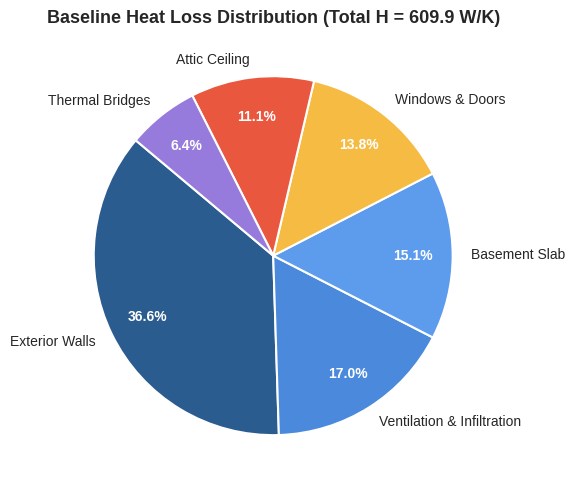

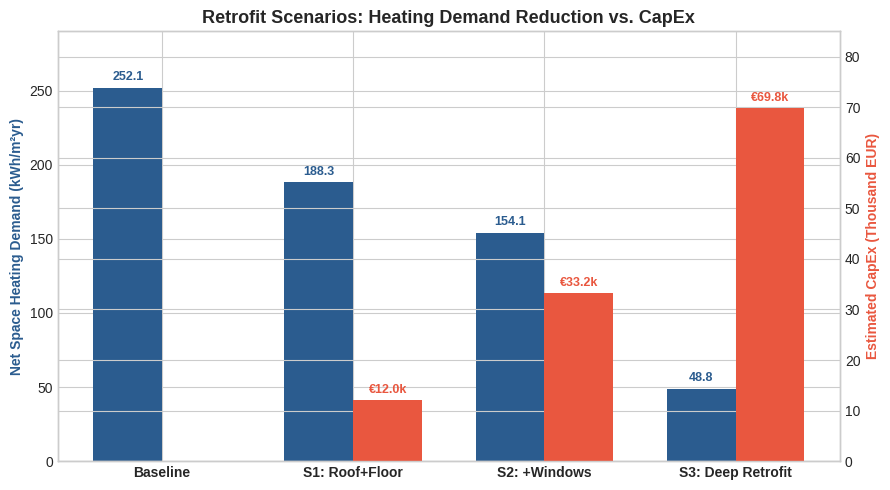


Saved charts: heat_loss_breakdown.png, scenario_comparison.png


In [3]:
"""
Residential Building Energy Assessment & Renovation Feasibility Study
Standards: ISO 6946 (U-values), EN ISO 13789 (Transmission), EN 12831 (Design Load)
Archetype: 1978 Detached Single-Family House (Central European / Bavaria Climate)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ==============================================================================
# 1. BUILDING GEOMETRY & BOUNDARY CONDITIONS
# ==============================================================================
class BuildingGeometry:
    def __init__(self):
        self.length = 10.0          # m
        self.width = 9.0            # m
        self.stories = 2
        self.clear_height = 2.60    # m per floor
        self.gross_height = 5.60    # m total exterior wall height

        # Areas (m2)
        self.a_floor = self.length * self.width                # 90.0 m2 (over unheated basement)
        self.a_roof = self.length * self.width                 # 90.0 m2 (ceiling under cold attic)
        self.a_cond = self.a_floor * self.stories              # 180.0 m2 conditioned floor area
        self.volume = self.a_cond * self.clear_height          # 468.0 m3 conditioned air volume

        # Fenestration by orientation (m2)
        self.windows = {
            "South": 4 * (1.5 * 1.4) + 1 * (2.2 * 2.1),        # 13.02 m2
            "East": 4 * (1.2 * 1.3),                           # 6.24 m2
            "West": 4 * (1.2 * 1.3),                           # 6.24 m2
            "North": 3 * (1.0 * 1.1) + 1 * (1.1 * 2.1),        # 5.61 m2
        }
        self.a_win = round(sum(self.windows.values()), 2)      # 31.11 m2

        # Exterior wall area (m2)
        perimeter = 2 * (self.length + self.width)             # 38.0 m
        self.a_wall_gross = round(perimeter * self.gross_height, 2)  # 212.80 m2
        self.a_wall = round(self.a_wall_gross - self.a_win, 2)       # 181.69 m2
        self.wwr = self.a_win / self.a_wall_gross              # 14.6%

        # Total thermal envelope area (m2)
        self.a_env = round(self.a_wall + self.a_roof + self.a_floor + self.a_win, 2)  # 392.80 m2


# ==============================================================================
# 2. ISO 6946 LAYER-BY-LAYER U-VALUE CALCULATOR
# ==============================================================================
def calculate_u_value(layers, r_si, r_se):
    """
    Calculates thermal transmittance U (W/m2K) per ISO 6946.
    layers: list of tuples (material_name, thickness_m, conductivity_W_mK)
    """
    r_layers = sum(d / lam for _, d, lam in layers)
    r_total = r_si + r_layers + r_se
    u_value = 1.0 / r_total
    return round(r_total, 4), round(u_value, 4)


def get_assemblies():
    # Baseline 1978 assemblies
    wall_base_layers = [
        ("Interior gypsum plaster", 0.015, 0.70),
        ("Hollow clay brick masonry", 0.300, 0.50),
        ("Exterior cement render", 0.020, 0.90),
    ]
    roof_base_layers = [
        ("Interior gypsum plaster", 0.015, 0.70),
        ("Reinforced concrete slab", 0.180, 2.10),
        ("Aged mineral wool (1978)", 0.040, 0.045),
    ]
    floor_base_layers = [
        ("Hardwood flooring", 0.015, 0.13),
        ("Cement screed", 0.050, 1.40),
        ("Reinforced concrete slab", 0.200, 2.10),
    ]

    # Retrofitted assemblies
    wall_new_layers = wall_base_layers + [("ETICS EPS/Mineral Wool", 0.160, 0.032)]
    roof_new_layers = roof_base_layers + [("High-density mineral wool", 0.240, 0.035)]
    floor_new_layers = floor_base_layers + [("PIR rigid insulation board", 0.100, 0.024)]

    assemblies = {
        "Wall (Baseline)": calculate_u_value(wall_base_layers, r_si=0.13, r_se=0.04),
        "Wall (160mm ETICS)": calculate_u_value(wall_new_layers, r_si=0.13, r_se=0.04),
        "Roof/Attic (Baseline)": calculate_u_value(roof_base_layers, r_si=0.10, r_se=0.10),
        "Roof/Attic (+240mm Wool)": calculate_u_value(roof_new_layers, r_si=0.10, r_se=0.10),
        "Basement Ceiling (Baseline)": calculate_u_value(floor_base_layers, r_si=0.17, r_se=0.17),
        "Basement Ceiling (+100mm PIR)": calculate_u_value(floor_new_layers, r_si=0.17, r_se=0.17),
        "Windows (1978 Double)": (0.3704, 2.7000),
        "Windows (Triple Low-E)": (1.2500, 0.8000),
    }
    return assemblies


# ==============================================================================
# 3. HEAT LOSS, ENERGY DEMAND & ECONOMIC SIMULATION
# ==============================================================================
def run_simulation():
    geo = BuildingGeometry()
    assemblies = get_assemblies()

    # Climate & Economic Parameters (Nuremberg/Bavaria, Germany)
    hdd_eff = 3100.0            # Effective Heating Degree Days (K*d/yr) net of solar/internal gains
    t_int = 20.0                # Design indoor temperature (C)
    t_ext = -12.0               # Design outdoor temperature (C)
    delta_t_design = t_int - t_ext  # 32.0 K

    boiler_eff = 0.85           # Existing non-condensing gas boiler efficiency
    gas_tariff = 0.12           # EUR/kWh
    co2_factor = 0.201          # kg CO2/kWh (natural gas)
    discount_rate = 0.03        # 3% real discount rate
    lifetime = 20               # years
    pvaf = (1 - (1 + discount_rate) ** (-lifetime)) / discount_rate

    # Temperature reduction factors (EN ISO 13789)
    b_wall, b_win, b_roof, b_floor = 1.00, 1.00, 0.90, 0.60

    scenarios = [
        {
            "name": "0. Baseline (1978 As-Built)",
            "short": "Baseline",
            "u_wall": assemblies["Wall (Baseline)"][1],
            "u_roof": assemblies["Roof/Attic (Baseline)"][1],
            "u_floor": assemblies["Basement Ceiling (Baseline)"][1],
            "u_win": assemblies["Windows (1978 Double)"][1],
            "du_tb": 0.10,      # Thermal bridge surcharge (W/m2K)
            "n_eff": 0.65,      # Effective air change rate (1/h)
            "capex": 0.0,
        },
        {
            "name": "1. Quick Wins (Roof + Basement)",
            "short": "S1: Roof+Floor",
            "u_wall": assemblies["Wall (Baseline)"][1],
            "u_roof": assemblies["Roof/Attic (+240mm Wool)"][1],
            "u_floor": assemblies["Basement Ceiling (+100mm PIR)"][1],
            "u_win": assemblies["Windows (1978 Double)"][1],
            "du_tb": 0.08,
            "n_eff": 0.60,
            "capex": (90 * 65) + (90 * 55) + 1200,  # EUR 12,000
        },
        {
            "name": "2. S1 + Triple-Glazed Windows",
            "short": "S2: +Windows",
            "u_wall": assemblies["Wall (Baseline)"][1],
            "u_roof": assemblies["Roof/Attic (+240mm Wool)"][1],
            "u_floor": assemblies["Basement Ceiling (+100mm PIR)"][1],
            "u_win": assemblies["Windows (Triple Low-E)"][1],
            "du_tb": 0.06,
            "n_eff": 0.50,
            "capex": 12000 + round(geo.a_win * 680),  # EUR 33,155
        },
        {
            "name": "3. Deep Retrofit (+ETICS + MVHR)",
            "short": "S3: Deep Retrofit",
            "u_wall": assemblies["Wall (160mm ETICS)"][1],
            "u_roof": assemblies["Roof/Attic (+240mm Wool)"][1],
            "u_floor": assemblies["Basement Ceiling (+100mm PIR)"][1],
            "u_win": assemblies["Windows (Triple Low-E)"][1],
            "du_tb": 0.03,
            "n_eff": 0.10 + 0.45 * (1 - 0.82),      # 0.181 1/h with 82% heat recovery
            "capex": 33155 + round(geo.a_wall * 155) + 8500,  # EUR 69,817
        },
    ]

    results = []
    breakdown_0 = {}

    for idx, s in enumerate(scenarios):
        ht_wall = s["u_wall"] * geo.a_wall * b_wall
        ht_roof = s["u_roof"] * geo.a_roof * b_roof
        ht_floor = s["u_floor"] * geo.a_floor * b_floor
        ht_win = s["u_win"] * geo.a_win * b_win
        ht_tb = s["du_tb"] * geo.a_env

        h_t = ht_wall + ht_roof + ht_floor + ht_win + ht_tb
        h_v = 0.34 * s["n_eff"] * geo.volume
        h_tot = h_t + h_v

        if idx == 0:
            breakdown_0 = {
                "Exterior Walls": ht_wall,
                "Ventilation & Infiltration": h_v,
                "Basement Slab": ht_floor,
                "Windows & Doors": ht_win,
                "Attic Ceiling": ht_roof,
                "Thermal Bridges": ht_tb,
            }

        design_load_kw = (h_tot * delta_t_design) / 1000.0
        q_net_kwh = (h_tot * hdd_eff * 24.0) / 1000.0
        q_final_kwh = q_net_kwh / boiler_eff
        spec_demand = q_net_kwh / geo.a_cond
        annual_cost = q_final_kwh * gas_tariff
        co2_tons = (q_final_kwh * co2_factor) / 1000.0

        results.append({
            "Scenario": s["name"],
            "Short": s["short"],
            "H_T (W/K)": round(h_t, 1),
            "H_V (W/K)": round(h_v, 1),
            "Peak Load (kW)": round(design_load_kw, 2),
            "Net Heating (kWh/yr)": round(q_net_kwh),
            "Specific Demand (kWh/m2yr)": round(spec_demand, 1),
            "Final Gas (kWh/yr)": round(q_final_kwh),
            "CapEx (EUR)": round(s["capex"]),
            "Annual Cost (EUR/yr)": round(annual_cost),
            "CO2 (t/yr)": round(co2_tons, 2),
        })

    df = pd.DataFrame(results)
    base_final = df.loc[0, "Final Gas (kWh/yr)"]
    base_cost = df.loc[0, "Annual Cost (EUR/yr)"]
    base_co2 = df.loc[0, "CO2 (t/yr)"]

    df["Savings (%)"] = round((1 - df["Final Gas (kWh/yr)"] / base_final) * 100, 1)
    df["Cost Saved (EUR/yr)"] = base_cost - df["Annual Cost (EUR/yr)"]
    df["Payback (yrs)"] = np.where(
        df["Cost Saved (EUR/yr)"] > 0,
        round(df["CapEx (EUR)"] / df["Cost Saved (EUR/yr)"], 1),
        np.nan,
    )
    df["20yr NPV (EUR)"] = np.where(
        df["CapEx (EUR)"] > 0,
        round(df["Cost Saved (EUR/yr)"] * pvaf - df["CapEx (EUR)"]),
        0,
    )
    df["CO2 Saved (t/yr)"] = round(base_co2 - df["CO2 (t/yr)"], 2)

    return geo, assemblies, breakdown_0, df


# ==============================================================================
# 4. PORTFOLIO VISUALIZATION GENERATOR
# ==============================================================================
def plot_charts(breakdown_0, df):
    plt.style.use("seaborn-v0_8-whitegrid")

    # Chart 1: Baseline Heat Loss Breakdown
    fig, ax = plt.subplots(figsize=(8, 5))
    labels = list(breakdown_0.keys())
    values = list(breakdown_0.values())
    colors = ["#2b5c8f", "#4a89dc", "#5d9cec", "#f6bb42", "#e9573f", "#967adc"]
    wedges, texts, autotexts = ax.pie(
        values,
        labels=labels,
        autopct="%1.1f%%",
        startangle=140,
        colors=colors,
        pctdistance=0.78,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    )
    for autotext in autotexts:
        autotext.set_color("white")
        autotext.set_fontweight("bold")
    ax.set_title("Baseline Heat Loss Distribution (Total H = 609.9 W/K)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("heat_loss_breakdown.png", dpi=300)
    plt.show()
    plt.close()

    # Chart 2: Heating Demand vs. CapEx Across Scenarios
    fig, ax1 = plt.subplots(figsize=(9, 5))
    x = np.arange(len(df))
    bars = ax1.bar(x - 0.18, df["Specific Demand (kWh/m2yr)"], width=0.36, color="#2b5c8f", label="Net Heating Demand (kWh/m²yr)")
    ax1.set_ylabel("Net Space Heating Demand (kWh/m²yr)", color="#2b5c8f", fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(df["Short"], fontweight="bold")
    ax1.set_ylim(0, 290)

    ax2 = ax1.twinx()
    bars2 = ax2.bar(x + 0.18, df["CapEx (EUR)"] / 1000.0, width=0.36, color="#e9573f", label="Renovation CapEx (k€)")
    ax2.set_ylabel("Estimated CapEx (Thousand EUR)", color="#e9573f", fontweight="bold")
    ax2.set_ylim(0, 85)

    for b in bars:
        ax1.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width()/2, b.get_height() + 5), ha="center", fontsize=9, fontweight="bold", color="#2b5c8f")
    for b in bars2:
        if b.get_height() > 0:
            ax2.annotate(f"€{b.get_height():.1f}k", (b.get_x() + b.get_width()/2, b.get_height() + 1.5), ha="center", fontsize=9, fontweight="bold", color="#e9573f")

    ax1.set_title("Retrofit Scenarios: Heating Demand Reduction vs. CapEx", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("scenario_comparison.png", dpi=300)
    plt.show()
    plt.close()


if __name__ == "__main__":
    geo, assemblies, breakdown_0, df = run_simulation()

    print("=== 1. BUILDING GEOMETRY ===")
    print(f"Conditioned Area: {geo.a_cond} m2 | Volume: {geo.volume} m3 | Envelope Area: {geo.a_env} m2")
    print(f"Net Wall: {geo.a_wall} m2 | Roof: {geo.a_roof} m2 | Floor: {geo.a_floor} m2 | Windows: {geo.a_win} m2 (WWR: {geo.wwr:.1%})\n")

    print("=== 2. ASSEMBLY U-VALUES (ISO 6946) ===")
    for name, (r_tot, u_val) in assemblies.items():
        print(f"{name:<30} | R_total = {r_tot:>6.3f} m2K/W | U = {u_val:>6.3f} W/m2K")

    print("\n=== 3. RETROFIT SCENARIO COMPARISON ===")
    print(df.to_string(index=False))

    plot_charts(breakdown_0, df)
    print("\nSaved charts: heat_loss_breakdown.png, scenario_comparison.png")